Initial attempt

In [ ]:
import numpy as np
from scipy.integrate import odeint
from scipy.fftpack import diff as psdiff
import

__kb__ = 1.380649e-23 #Boltzmann constant in J/K
__c__ = 3e8 # Speed of light in m/s

_alpha =
_beta =
_N =
_L =
_debris_vel =
_pn_potential =
_G =
_dt =
_t0 =
_t_final =

def forced_kdv_exact(x, c):
    """Profile of the exact solution to the KdV for a single soliton on the real line."""
    u = 0.5*c*np.cosh(0.5*np.sqrt(c)*x)**(-2)
    return u

def normalised_plasma_potential(e, tau, vd, G):
    """Normalised plasma potential for the normalised forced KdV equation."""
    np_potential = s_potential * np.exp(-1*r/debye_len) * (e/__kb__ * T_e)

    return np_potential

def forcing_term(e, tau, vd, G, nplasma_pot):
    """Forcing term for the normalised forced KdV equation."""
    np_potential = normalised_plasma_potential()
    f = np_potential * np.exp(-1 * ((e - vd * tau)/ G)**2)
    return f

def normalised_forced_kdv(u, f, L, s, a, b):
    """Differential equations for the normalised forced KdV equation, discretized in x.
    `u` is the solution array, `f` is the forcing function,
    `L` is the length of the periodic domain,"""

    # Compute the x derivatives using the pseudo-spectral method.
    du_de = psdiff(u, period=L)
    du_de3 = psdiff(u, period=L, order=3)
    df_de = psdiff(f, period=L)

    # Compute du/dtau by rearranging normalised forced kdv equation.
    du_dtau = 1/2*s*df_de - a*s*u*du_de - b*(s**3)*du_de3

    return du_dtau

def kdv_solution(u0, t, L):
    """Use odeint to solve the KdV equation on a periodic domain.

    `u0` is initial condition, `t` is the array of time values at which
    the solution is to be computed, and `L` is the length of the periodic
    domain."""

    sol = odeint(kdv, u0, t, args=(L,), mxstep=5000)
    return sol


if __name__ == "__main__":
    # Set the size of the domain, and create the discretized grid.
    L = 2*np.pi
    N = 64
    dx = L / (N - 1.0)
    x = np.linspace(0, (1-1.0/N)*L, N)

    # Set the initial conditions.
    # Not exact for two solitons on a periodic domain, but close enough...
    u0 = forced_kdv_exact(x-0.33*L, 0.75) + forced_kdv_exact(x-0.65*L, 0.4)

    # Set the time sample grid.
    T = 200
    t = np.linspace(0, T, 501)

    print("Computing the solution.")
    sol = kdv_solution(u0, t, L)


    print("Plotting.")

    import matplotlib.pyplot as plt

    plt.figure(figsize=(6,5))
    plt.imshow(sol[::-1, :], extent=[-1*L,L,-1*T,T])
    plt.colorbar()
    plt.xlabel('x')
    plt.ylabel('t')
    plt.axis('auto')
    plt.title('Korteweg-de Vries on a Periodic Domain')
    plt.show()

Plotting.


ValueError: Argument Z must be 2-dimensional.

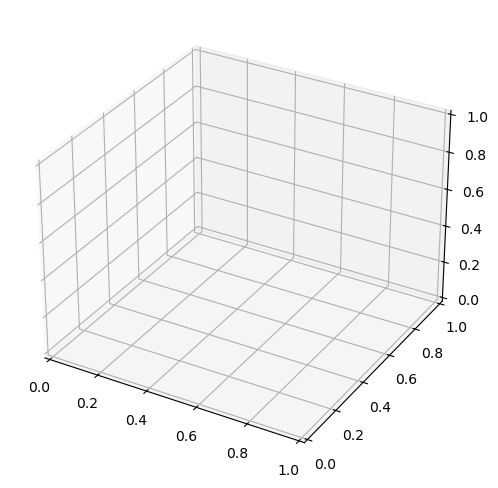

# Plasma Potential Calculation
## Recreating figure 1 from NASA paper


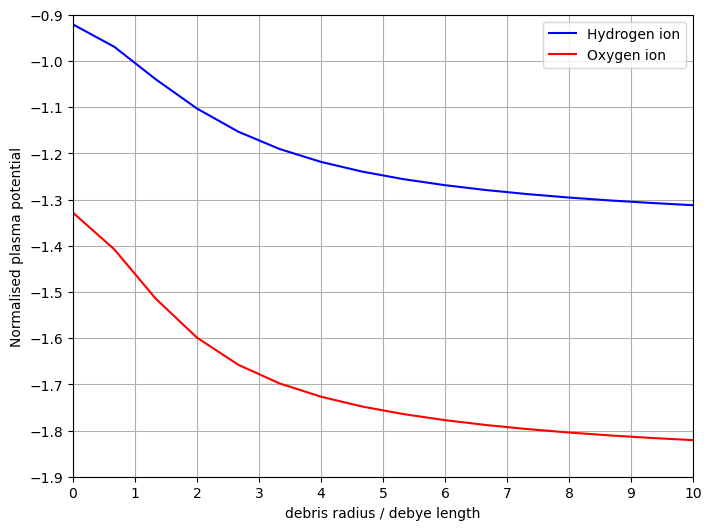

In [88]:
from scipy.optimize import brentq
import numpy as np
import matplotlib.pyplot as plt

def surface_potential_equation(x, mass_ratio, s, a):
    """Equation 32 from the NASA paper in the form 0 = f(x) where f(x) is equal to g(x) - A(1-B * e(Cx), this equation is then put through brents method to identify the roots of the function """
    return np.exp(x) - np.sqrt(mass_ratio) * ((s/a)**2) * ( 1 - ((s**2 - a**2)/s**2) * np.exp( (a**2 / (s**2 - a**2)) * x ))


#consants
__me__ = 9.1093837139e-31 # Electron mass in kg
__mh__ = 1.67262192595e-27 # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27 # Oxygen ion mass in kg
debye_length = 1 # Example value for debye radius

r = debye_length # Distance from the debris surface the potnetial is felt too, which for plasma is the debye length, this is used to normalise the plasma potential

a_array = np.linspace( 1e-3, 10, 16) # Array of debris radii from 0.00001 to 10 in 16 steps

phi_ox= np.zeros(len(a_array))
phi_h = np.zeros(len(a_array))

# Calculate the normalised plasma potential for each debris radius
for i, a in enumerate(a_array):
    mass_ratio = __me__ / __mo__
    s = a + debye_length
    x_solution = brentq(surface_potential_equation, -20, 0, args=(mass_ratio, s, a))
    phi_ox[i] = x_solution * np.exp(-r/ debye_length)  # normalised plasma potential

for i, a in enumerate(a_array):
    mass_ratio = __me__ / __mh__
    s = a + debye_length
    x_solution = brentq(surface_potential_equation, -20, 0, args=(mass_ratio, s, a))
    phi_h[i] = x_solution * np.exp(-r/ debye_length)  # normalised plasma potential


# PLOTTING
plt.figure(figsize=(8, 6))
plt.grid()
plt.plot(a_array / debye_length, phi_h, label="Hydrogen ion", color="blue")
plt.plot(a_array/ debye_length, phi_ox, label="Oxygen ion", color="red")
plt.xlabel("debris radius / debye length")
plt.ylabel("Normalised plasma potential")
plt.xticks(np.arange(0, 11, 1))
plt.yticks(np.arange(-2, 1, 0.1))
plt.xlim(0, 10)
plt.ylim( -1.9,-0.9)
plt.legend()
plt.show()

### Functionisng the Normalised Plasma Potential Calculation & Validating against NASA paper values (Table 6)

In [3]:
from scipy.optimize import brentq
import numpy as np

def normalised_plasma_potential(a, debye_length, mass_ratio, potential_radius = None):
    """Calculates the normalised plasma potential for a given debris radius, debye length, and mass ratio."""
    def eqn_surface_potential(x, mass_ratio, s, a):
        """Equation 32 from the NASA paper in the form 0 = f(x) where f(x) is equal to g(x) - A(1-B * e(Cx), this equation is then put through brents method to identify the roots of the function, eφ/kT"""
        return np.exp(x) - np.sqrt(mass_ratio) * (s/a)**2  * ( 1 - ((s**2 - a**2)/s**2) * np.exp( (a**2 / (s**2 - a**2)) * x ))

    # If potential_radius is not provided, it defaults to the debye_length.
    if potential_radius is None:
        potential_radius = debye_length

    s = a + debye_length

    x_sol = brentq(eqn_surface_potential, -10, 0, args=(mass_ratio, s, a))
    phi_np = x_sol * np.exp(-potential_radius/debye_length)  # normalised plasma potential

    return phi_np

# ========= Validation against NASA paper values (Table 6) =========
__me__ = 9.1093837139e-31 # Electron mass in kg
__mh__ = 1.67262192595e-27 # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27 # Oxygen ion mass in kg

mass_ratio_o = __me__ / __mo__
mass_ratio_h = __me__ / __mh__

# values extracted from NASA paper Table 6 f

debris_diameters= [10e-2, 5e-2, 1e-2, 5e-3, 1e-3] # Debris diameters in meters
debye_lengths = [.83e-2, 1.38e-2, 4.36e-2, 23504e-2] # Debye lengths for Low LEO, Low LEO I, Low LEO II, and GEO respectively in meters

lowleo_phi_values = [-1.77, -1.68, -1.40, -1.35, -1.33]
lowleoi_phi_values = [-1.20, -1.08, -0.94, -0.93, -0.92]
lowleoii_phi_values = [-1.02, -0.96, -0.92, -0.92, -0.92]

debris_radii = [d/2 for d in debris_diameters] # Debris radii in meters

# Low LEO
print("=Normalised plasma potential calculations for Low LEO region (Oxygen)=:")
for a in debris_radii:
    phi_lowleo = normalised_plasma_potential(a, debye_lengths[0], mass_ratio_o)
    uncertainty = abs(phi_lowleo - lowleo_phi_values[debris_radii.index(a)])
    print(f"Debris radius: {a:.1e} m, Normalised plasma potential: {phi_lowleo:.3f}, uncertainty: {uncertainty:.3f}")

# Low LEO I
print("\n=Normalised plasma potential calculations for Low LEO I region (Hydrogen)=:")
for a in debris_radii:
    phi_lowleoi = normalised_plasma_potential(a, debye_lengths[1], mass_ratio_h)
    uncertainty = abs(phi_lowleoi - lowleoi_phi_values[debris_radii.index(a)])
    print(f"Debris radius: {a:.1e} m, Normalised plasma potential: {phi_lowleoi:.3f}, uncertainty: {uncertainty:.3f}")

# Low LEO II
print("\n=Normalised plasma potential calculations for Low LEO II region (Hydrogen)=:")
for a in debris_radii:
    phi_lowleoii = normalised_plasma_potential(a, debye_lengths[2], mass_ratio_h)
    uncertainty = abs(phi_lowleoii - lowleoii_phi_values[debris_radii.index(a)])
    print(f"Debris radius: {a:.1e} m, Normalised plasma potential: {phi_lowleoii:.3f}, uncertainty: {uncertainty:.3f}")

=Normalised plasma potential calculations for Low LEO region (Oxygen)=:
Debris radius: 5.0e-02 m, Normalised plasma potential: -1.778, uncertainty: 0.008
Debris radius: 2.5e-02 m, Normalised plasma potential: -1.680, uncertainty: 0.000
Debris radius: 5.0e-03 m, Normalised plasma potential: -1.398, uncertainty: 0.002
Debris radius: 2.5e-03 m, Normalised plasma potential: -1.353, uncertainty: 0.003
Debris radius: 5.0e-04 m, Normalised plasma potential: -1.330, uncertainty: 0.000

=Normalised plasma potential calculations for Low LEO I region (Hydrogen)=:
Debris radius: 5.0e-02 m, Normalised plasma potential: -1.204, uncertainty: 0.004
Debris radius: 2.5e-02 m, Normalised plasma potential: -1.086, uncertainty: 0.006
Debris radius: 5.0e-03 m, Normalised plasma potential: -0.941, uncertainty: 0.001
Debris radius: 2.5e-03 m, Normalised plasma potential: -0.927, uncertainty: 0.003
Debris radius: 5.0e-04 m, Normalised plasma potential: -0.921, uncertainty: 0.001

=Normalised plasma potential c

calculating forcing term in low leo


Plotting.


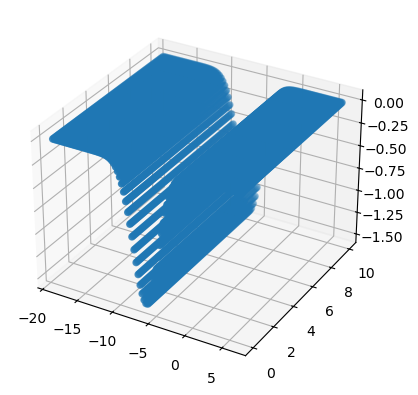

In [48]:
from scipy.optimize import brentq
import numpy as np
import matplotlib.pyplot as plt

def forcing_term(np_potential, xi, tau, vd, G):
    return np_potential * np.exp(-1 * ((e - (vd * tau))/ G)**2)


a = 0.01 # Debris radius in m
L =  2*np.pi# size of the domain
vd = 0
N = 100

tau = np.linspace(0, L, N)
x = np.linspace(-3* L, L, N)
tau = np.linspace(0, 10, N)

e = ( np.pi / L ) * (x + L)

debye_length = .83e-2
__me__ = 9.1093837139e-31 # Electron mass in kg
__mh__ = 1.67262192595e-27 # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27 # Oxygen ion mass in kg
mass_ratio_o = __me__ / __mo__


G = a / debye_length # Normalised forcing width
np_potential = normalised_plasma_potential(a, debye_length, mass_ratio_o)


print("Plotting.")

# 3D surface plot
X, Tm = np.meshgrid(x, t)
f = forcing_term(np_potential, X, Tm, vd, G)

fig, ax = plt.subplots(subplot_kw={'projection':'3d'})
ax.scatter(X, Tm, f)
plt.show()



### Imports & variables

In [50]:
import pandas as pd
def initialise_ionosphere_region(df, region):
    """ takes a dataframe of ionospheric properties and pulls the associated properties for a given region. making the necessary calculations required to run simulation CURRENTLY NOT ABLE TO HANDLE GEO"""

    # Pulls property name and values into a list and numpy array respectively
    value = df_ionosphere[region].to_numpy()
    properties =  df_ionosphere["Properties"].to_list()

    # Creates a dictionary of the properties and values for the given region
    plasma_properties = dict(zip(properties, value))
    return plasma_properties

# Upload the Ionosphere properties from the Excel file
df_ionosphere= pd.read_excel(r'Ionosphere prop.xltx')
display(df_ionosphere)

# Pulls the properties for the Low LEO region into a dictionary
plasma_prop = initialise_ionosphere_region(df_ionosphere, "Low LEO")

,Properties,Low LEO,High LEO I,High LEO II,GEO
0,Altitude,700,1200,1400,35786
1,Latitude,"0,50",0-55,0-55,0-90
2,Electron Density,200000,100000,10000,1
3,Electron Tempreture,0.25,0.35,0.35,1000
4,Ion Species,O,H,H,OH
5,Ion Mass,16,1,1,"16,1"
6,Debye Length,0.83,1.38,4.36,23504
7,Debris Velocity Circular Orbit,7.51,7.26,7.16,3.08
8,Ion Acoustic Velocity,1.22,5.75,5.75,"77.43 , 309.73"


In [57]:
import numpy as np
from numpy.fft import rfft, irfft
from numpy import pi, cos, linspace, arange
from scipy.fftpack import diff as psdiff
import pandas as pd
import matplotlib.pyplot as plt
from IPython.core.pylabtools import figsize
from scipy.optimize import brentq


# =============================== Inputs ================================

# Global constants
__kb__ = 1.380649e-23  #Boltzmann constant in J/K
__c__ = 299792458  # Speed of light in m/s
__me__ = 9.1093837139e-31 # Electron mass in kg
__mh__ = 1.67262192595e-27 # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27 # Oxygen ion mass in kg

# Physical parameters
a = 0.01 # Debris radius in m
alpha = 1.0051
beta = 0.4925
debris_vel = 0 # Debris velocity in m/s
np_potential = None # Normalised plasma potential, if None, it will be automatically calculated.

# Simulation parameters
N = 1024 # number of discretised points in the domain
L = 20 # size of the domain
G = a / plasma_prop["Debye Length"] # Normalised forcing width
tau_step = 2 # s
tau_inital = 0 # s
tau_final = 120 # s


# Determine the ion species and set the corresponding ion mass and mass ratio
if plasma_prop["Ion Species"] == "O":
    mi = __mo__
    mass_ratio = __me__ / __mo__
elif plasma_prop["Ion Species"] == "H":
    mi= __mh__
    mass_ratio = __me__ / __mh__
else:
    raise ValueError("Ion species not recognised. Please use 'O' for Oxygen or 'H' for Hydrogen.")

# if up
if np_potential is None:
    np_potential = normalised_plasma_potential(a, plasma_prop["Debye Length"], mass_ratio)


# ================================ Functions ================================

def normalised_plasma_potential(a, debye_length, mass_ratio, potential_radius = None):
    """Calculates the normalised plasma potential for a given debris radius, debye length, and mass ratio."""
    def eqn_surface_potential(x, mass_ratio, s, a):
        """Equation 32 from the NASA paper in the form 0 = f(x) where f(x) is equal to g(x) - A(1-B * e(Cx), this equation is then put through brents method to identify the roots of the function, eφ/kT"""
        return np.exp(x) - np.sqrt(mass_ratio) * (s/a)**2  * ( 1 - ((s**2 - a**2)/s**2) * np.exp( (a**2 / (s**2 - a**2)) * x ))

    # If potential_radius is not provided, it defaults to the debye_length.
    if potential_radius is None:
        potential_radius = debye_length

    s = a + debye_length

    x_sol = brentq(eqn_surface_potential, -10, 0, args=(mass_ratio, s, a))
    phi_np = x_sol * np.exp(-potential_radius/debye_length)  # normalised plasma potential

    return phi_np

def forcing_term(np_potential, xi, tau, vd, G):
    return np_potential * np.exp(-1 * ((xi - (vd * tau))/ G)**2)

def fkdv_exact_solution(a, x, K = 0.6124):
    return a * ((np.cosh(K * x)**0.5)**2)

def ck_solutions(u0, time_array, alpha, beta, s, k, f, dt):
    """Use the Crank-Nicolson scheme to solve the normalised forced KdV equation on a periodic domain."""

    #initalisng the soltuion array with the initial condition
    sol = np.zeros((len(time_array)))
    sol[1] = u0

    # pre-calculating coefficients
    _ck_beta = dt * beta * j * s**3 * k**3
    _ck_z = dt * j * s * k

    # iterate over the time array to compute the solution at each time step
    for i in range(1,len(time_array)):
        sol[i+1] = ifft( ((1 - _ck_beta)**-1) * ( (1 + _ck_beta) * fft(sol[i-1]) - alpha * _ck_z * fft(sol[i])**2 + _ck_z * fft(f) ) )

    return sol

#================================= Main ================================

if __name__ == "__main__":

    # Creating the normalise spae and time arrays
    t = np.linspace(tau_inital, tau_final, N)
    x = np.linspace(-1 * L, L, N)  / debye_length

    # Defining mesh space & waven numbers
    s = np.pi / L
    xi =  s * (x + L)
    dxi = 2 * np.pi / N

    k = np.fft.fftfreq(N, d=1/N)

    # Intialisng with an exact soltuion fot U
    u0 = fkdv_exact_solution(a, x)

    # Calculating a forcing term for the debris
    np_potential = normalised_plasma_potential(a, plasma_prop["Debye Length"], mass_ratio)
    f = forcing_term(np_potential, xi, t, vd, G)

    # Propogate exact solution forward in time with CK scheme
    sol = ck_solutions(u0= u0,
                       time_array=t,
                       alpha=alpha,
                       beta=beta,
                       s=s,
                       k=k,
                       f=f,
                       dt=tau_step
                       )

    print("plotting")
    fig, ax = plt.subplots(subplot_kw={'projection':'3d'})
    ax.scatter(x, t, sol)
    plt.show()


    """
    # visualisng results
    plt.figure(figsize=(6,5))
    plt.imshow(sol, extent=[0,L,0,T])
    plt.colorbar()
    plt.xlabel('x')
    plt.ylabel('t')
    plt.axis('auto')
    plt.title('Korteweg-de Vries on a Periodic Domain')
    plt.show()
    """

C:\Users\prsew\AppData\Local\Temp\ipykernel_4512\4264729035.py:74: RuntimeWarning: overflow encountered in cosh
  return a * ((np.cosh(K * x)**0.5)**2)


ValueError: setting an array element with a sequence.

### Functions

### Main